In [1]:
!pip -q install torch torchvision matplotlib pandas pillow

In [2]:
import os, io, zipfile, shutil, random
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
print('PyTorch:', torch.__version__)

PyTorch: 2.11.0+cpu


In [3]:
uploaded = files.upload()
zip_name = next((name for name in uploaded if name.lower().endswith('.zip')), None)
if zip_name is None:
    raise ValueError('Wgraj plik ZIP ze zdjęciami')
base = Path('/content/lab03_data')
if base.exists():
    shutil.rmtree(base)
base.mkdir(parents=True)
with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as archive:
    for item in archive.infolist():
        target = (base / item.filename).resolve()
        if not target.is_relative_to(base.resolve()):
            raise ValueError('Nieprawidłowa ścieżka w ZIP')
    archive.extractall(base)
roots = [p for p in [base, *base.iterdir()] if p.is_dir() and (p / 'auta').is_dir() and (p / 'motory').is_dir()]
if len(roots) != 1:
    raise ValueError('Nie znaleziono folderów auta i motory')
ROOT = roots[0]
print(ROOT)

Saving moje dane.zip to moje dane.zip
/content/lab03_data/moje dane


In [5]:
ds_raw = datasets.ImageFolder(ROOT)
print('Klasy:', ds_raw.classes)
print('class_to_idx:', ds_raw.class_to_idx)
print('Liczba obrazów:', len(ds_raw))
print('Liczność klas:', dict(zip(ds_raw.classes, (Counter(ds_raw.targets)[i] for i in range(len(ds_raw.classes))))))
bad = []
for path, label in ds_raw.samples:
    try:
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            image.convert('RGB').load()
    except Exception as e:
        bad.append((path, str(e)))
print('Nieczytelne obrazy:', bad)
assert not bad
assert len(ds_raw.classes) == 2
assert all(n >= 30 for n in Counter(ds_raw.targets).values())

Klasy: ['auta', 'motory']
class_to_idx: {'auta': 0, 'motory': 1}
Liczba obrazów: 60
Liczność klas: {'auta': 30, 'motory': 30}
Nieczytelne obrazy: []


In [6]:
indices_train, indices_val = [], []
for cls in range(len(ds_raw.classes)):
    indices = [i for i, target in enumerate(ds_raw.targets) if target == cls]
    rng = np.random.default_rng(42 + cls)
    rng.shuffle(indices)
    cut = int(0.8 * len(indices))
    indices_train.extend(indices[:cut])
    indices_val.extend(indices[cut:])
assert set(indices_train).isdisjoint(indices_val)

mean = [0.5, 0.5, 0.5]
std = [0.5, 0.5, 0.5]
eval_tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])
train_tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_ds = Subset(datasets.ImageFolder(ROOT, transform=train_tf), indices_train)
val_ds = Subset(datasets.ImageFolder(ROOT, transform=eval_tf), indices_val)
train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False, num_workers=0)
print('Trening:', len(train_ds), 'Walidacja:', len(val_ds))

Trening: 48 Walidacja: 12


In [7]:
counts_train = Counter(ds_raw.targets[i] for i in indices_train)
counts_val = Counter(ds_raw.targets[i] for i in indices_val)
stats = pd.DataFrame({
    'Klasa': ds_raw.classes,
    'Indeks': list(range(len(ds_raw.classes))),
    'Wszystkie': [Counter(ds_raw.targets)[i] for i in range(len(ds_raw.classes))],
    'Trening': [counts_train[i] for i in range(len(ds_raw.classes))],
    'Walidacja': [counts_val[i] for i in range(len(ds_raw.classes))]
})
display(stats)
print('Liczba klas:', len(ds_raw.classes))
print('class_to_idx:', ds_raw.class_to_idx)
print('Rozmiar tensora jednego obrazu:', tuple(train_ds[0][0].shape))

,Klasa,Indeks,Wszystkie,Trening,Walidacja
0,auta,0,30,24,6
1,motory,1,30,24,6


Liczba klas: 2
class_to_idx: {'auta': 0, 'motory': 1}
Rozmiar tensora jednego obrazu: (3, 128, 128)


Trening - kształt: (8, 3, 128, 128) typ: torch.float32
Trening - zakres: -1.0 1.0
Trening - etykiety: [0, 0, 0, 1, 1, 0, 0, 1]
Walidacja - kształt: (8, 3, 128, 128) typ: torch.float32
Walidacja - zakres: -1.0 1.0
Walidacja - etykiety: [0, 0, 0, 0, 0, 0, 1, 1]
Nazwy klas: ['auta', 'motory']


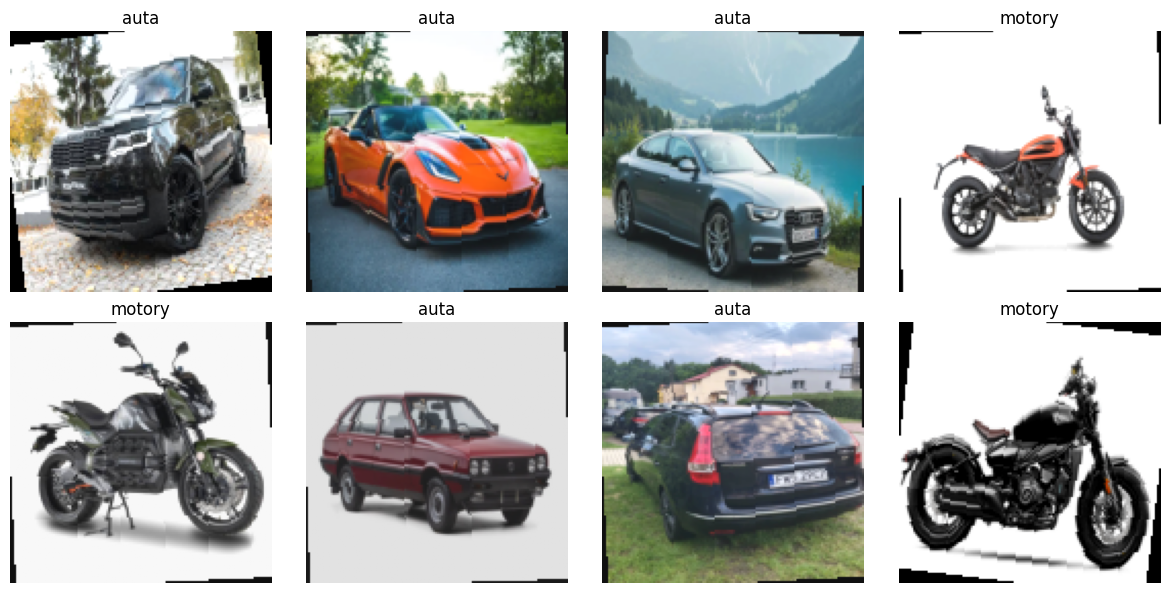

In [8]:
xb, yb = next(iter(train_loader))
xv, yv = next(iter(val_loader))
print('Trening - kształt:', tuple(xb.shape), 'typ:', xb.dtype)
print('Trening - zakres:', float(xb.min()), float(xb.max()))
print('Trening - etykiety:', yb.tolist())
print('Walidacja - kształt:', tuple(xv.shape), 'typ:', xv.dtype)
print('Walidacja - zakres:', float(xv.min()), float(xv.max()))
print('Walidacja - etykiety:', yv.tolist())
print('Nazwy klas:', ds_raw.classes)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, image, target in zip(axes.flat, xb, yb):
    image = (image * 0.5 + 0.5).clamp(0, 1)
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title(ds_raw.classes[int(target)])
    ax.axis('off')
plt.tight_layout()
plt.show()

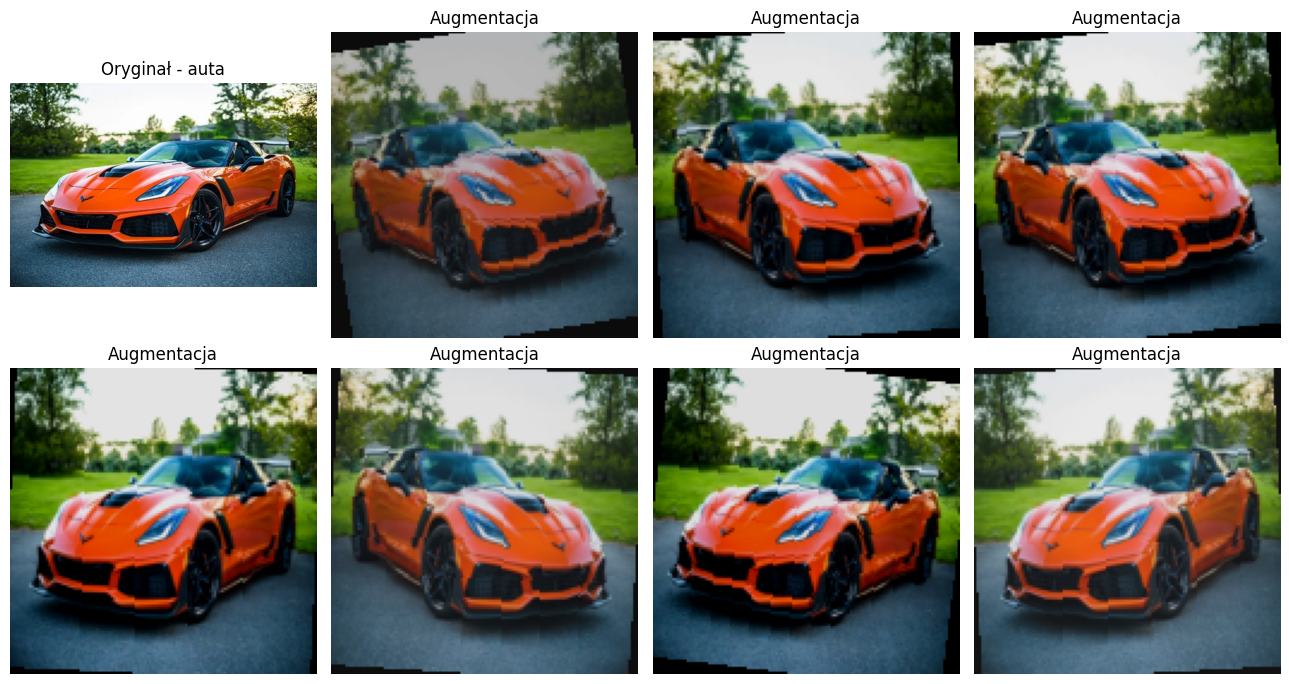

In [9]:
image_path, label = ds_raw.samples[indices_train[0]]
with Image.open(image_path) as image:
    raw = image.convert('RGB')
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
axes[0, 0].imshow(raw)
axes[0, 0].set_title('Oryginał - ' + ds_raw.classes[label])
axes[0, 0].axis('off')
for ax in axes.flat[1:]:
    tensor = train_tf(raw)
    ax.imshow((tensor * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy())
    ax.set_title('Augmentacja')
    ax.axis('off')
plt.tight_layout()
plt.show()

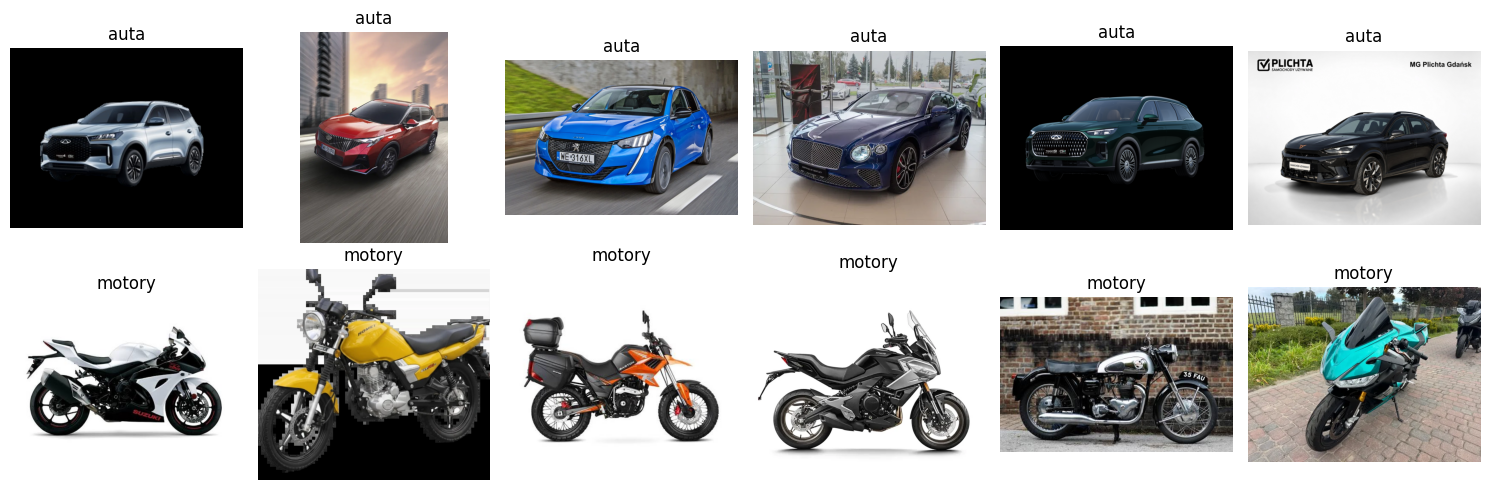

Podział: 48 treningowych i 12 walidacyjnych


In [10]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for row, class_name in enumerate(ds_raw.classes):
    examples = [ds_raw.samples[i][0] for i in indices_val if ds_raw.targets[i] == row][:6]
    for ax, path in zip(axes[row], examples):
        with Image.open(path) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(class_name)
        ax.axis('off')
plt.tight_layout()
plt.show()
print('Podział:', len(indices_train), 'treningowych i', len(indices_val), 'walidacyjnych')